# COMET GRN feature figures

Standalone, runnable figures on the COMET GRN output vs CellOracle (Paul15).

1. **Regulators per gene** (in-degree distribution) — COMET vs CellOracle.
2. **Magnitude- vs sign-based agreement** — shows the (weak) agreement with
   CellOracle on shared edges is driven by edge *magnitude*, not *sign*.

**Convention:** "top edges" / "edge strength" always means **|coefficient|** —
strong activators and strong repressors both count.

Edit `COMET_BASE` / `CO_REF` to point at a different run (e.g. `..._test2`).

In [7]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter
from scipy.stats import spearmanr

COMET_BASE = "/home/elicanter/paul2015_outputs_newmethod_d6"
CO_REF     = "/home/elicanter/datasets/paul2015data/celloracle_reference"
EPS = 1e-8

# ---- palette (colorblind-safe, from the dataviz reference palette) ----
COMET_C, CO_C = "#2a78d6", "#eda100"      # blue / yellow
INK, SUB, GRID = "#0b0b0b", "#52514e", "#e6e6e2"
plt.rcParams.update({
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb",
    "axes.edgecolor": SUB, "text.color": INK, "axes.labelcolor": INK,
    "xtick.color": SUB, "ytick.color": SUB, "font.size": 10,
    "axes.spines.top": False, "axes.spines.right": False,
})

In [8]:
# ---- load COMET GRN tensors ----
A_base    = np.load(f"{COMET_BASE}/A_base.npy")      # (G, T) shared base
A_dict    = np.load(f"{COMET_BASE}/A_dict.npy")      # (D, G, T) residual modules
A_learned = np.load(f"{COMET_BASE}/A_learned.npy")   # (G, T) population GRN
mix_weights = np.load(f"{COMET_BASE}/mix_weights.npy")  # (n_cells, D), simplex
A_genes = np.load(f"{COMET_BASE}/A_genes.npy", allow_pickle=True).astype(str)
A_tfs   = np.load(f"{COMET_BASE}/A_tfs.npy",   allow_pickle=True).astype(str)
G, T = A_learned.shape
gene_pos = {g: i for i, g in enumerate(A_genes)}
tf_pos   = {t: i for i, t in enumerate(A_tfs)}
print(f"COMET: {G} genes x {T} TFs, D={A_dict.shape[0]} atoms, {mix_weights.shape[0]} cells")

# ---- build CellOracle pooled global GRN from filtered per-cluster edges ----
def edges_to_matrix(df, value_col="coef_mean"):
    """Long CellOracle edge table -> dense signed (G, T) matrix on the shared universe."""
    mat = np.zeros((G, T), dtype=np.float32)
    df = df[df["target"].isin(gene_pos) & df["source"].isin(tf_pos)]
    mat[df["target"].map(gene_pos).to_numpy(), df["source"].map(tf_pos).to_numpy()] = df[value_col].to_numpy()
    return mat

edir = f"{CO_REF}/edges_by_cluster"
cluster_names = sorted(f[:-4] for f in os.listdir(edir))
co_cluster_mats = {cl: edges_to_matrix(pd.read_csv(f"{edir}/{cl}.csv")) for cl in cluster_names}

# cell-count-weighted pool (CellOracle has no native single-population GRN)
cell_meta = pd.read_csv(f"{CO_REF}/cell_metadata.csv", index_col=0)
sizes = cell_meta["paul15_clusters"].value_counts()
w = np.array([sizes.get(cl, 0) for cl in co_cluster_mats], dtype=float); w /= w.sum()
co_global = np.tensordot(w, np.stack(list(co_cluster_mats.values())), axes=1)  # (G, T)

comet_mask = np.abs(A_learned) > EPS
co_mask    = np.abs(co_global) > EPS
print(f"COMET density {comet_mask.mean():.3f} | CellOracle density {co_mask.mean():.3f}")

COMET: 1850 genes x 90 TFs, D=6 atoms, 2671 cells
COMET density 0.440 | CellOracle density 0.082


## Figure 1 — Regulators per gene (in-degree)

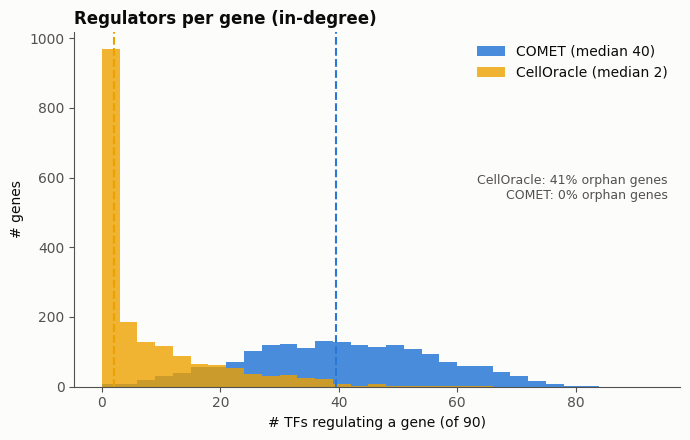

In [9]:
in_comet = comet_mask.sum(axis=1)   # # TFs regulating each gene
in_co    = co_mask.sum(axis=1)

fig, ax = plt.subplots(figsize=(7, 4.5))
bins = np.arange(0, T + 4, 3)
ax.hist(in_comet, bins=bins, color=COMET_C, alpha=0.85, label=f"COMET (median {np.median(in_comet):.0f})")
ax.hist(in_co,    bins=bins, color=CO_C,    alpha=0.80, label=f"CellOracle (median {np.median(in_co):.0f})")
ax.axvline(np.median(in_comet), color=COMET_C, ls="--", lw=1.5)
ax.axvline(np.median(in_co),    color=CO_C,    ls="--", lw=1.5)
ax.set_xlabel(f"# TFs regulating a gene (of {T})")
ax.set_ylabel("# genes")
ax.set_title("Regulators per gene (in-degree)", fontweight="bold", loc="left")
ax.legend(frameon=False)
ax.text(0.98, 0.60,
        f"CellOracle: {(in_co == 0).mean()*100:.0f}% orphan genes\n"
        f"COMET: {(in_comet == 0).mean()*100:.0f}% orphan genes",
        transform=ax.transAxes, ha="right", va="top", fontsize=9, color=SUB)
fig.tight_layout()
fig.savefig("regulators_per_gene.png", dpi=150, bbox_inches="tight")
plt.show()

## Figure 2 — Agreement with CellOracle is magnitude-based, not sign-based

On edges both methods keep, compare **signed** Spearman (uses ±) vs **unsigned**
Spearman (|coef|), across increasingly strict "both edges strong" magnitude cutoffs.
If unsigned stays positive while signed collapses to ~0, the agreement is about
*how strong* an edge is, not *which direction* it points.

In [10]:
shared = comet_mask & co_mask
x_all, y_all = A_learned[shared], co_global[shared]
print(f"{shared.sum():,} shared edges")

# signed / unsigned Spearman + sign-agreement at nested magnitude cutoffs
quantiles = [0.0, 0.5, 0.75, 0.9]
rows = []
for q in quantiles:
    tx, ty = np.quantile(np.abs(x_all), q), np.quantile(np.abs(y_all), q)
    sel = (np.abs(x_all) >= tx) & (np.abs(y_all) >= ty)
    xs, ys = x_all[sel], y_all[sel]
    rows.append(dict(
        label=f"top {int((1-q)*100)}%", n=int(sel.sum()),
        signed=spearmanr(xs, ys).correlation,
        unsigned=spearmanr(np.abs(xs), np.abs(ys)).correlation,
        sign_agree=(np.sign(xs) == np.sign(ys)).mean(),
    ))
res = pd.DataFrame(rows)
print(res.to_string(index=False))

13,327 shared edges
   label     n    signed  unsigned  sign_agree
top 100% 13327  0.091257  0.168848    0.585803
 top 50%  3601 -0.001748  0.134682    0.620661
 top 25%  1174 -0.050818  0.126453    0.632879
  top 9%   281 -0.033307  0.122254    0.622776


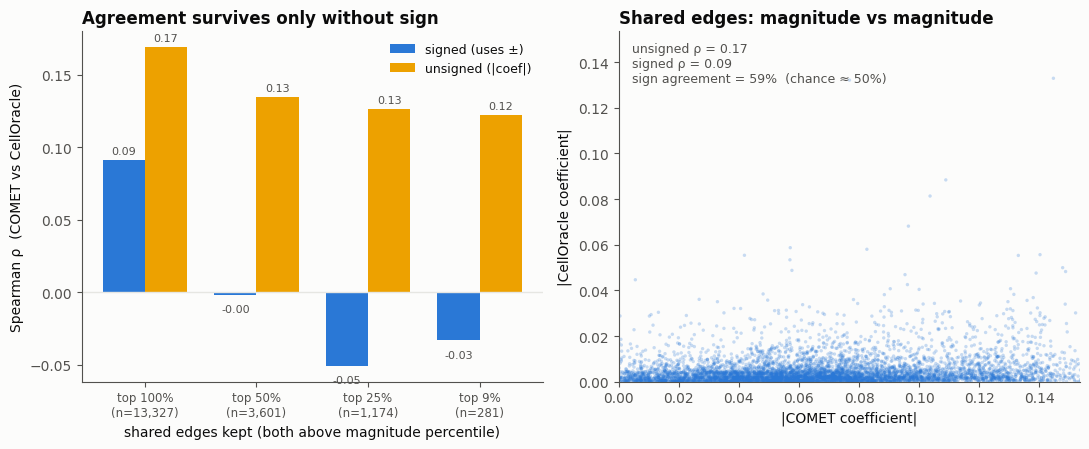

In [11]:
fig, (axL, axR) = plt.subplots(1, 2, figsize=(11, 4.6))

# -- left: signed vs unsigned Spearman across magnitude cutoffs --
xpos = np.arange(len(res)); bw = 0.38
axL.axhline(0, color=GRID, lw=1)
axL.bar(xpos - bw/2, res["signed"],   bw, color=COMET_C, label="signed (uses ±)")
axL.bar(xpos + bw/2, res["unsigned"], bw, color=CO_C,    label="unsigned (|coef|)")
for xi, s, u in zip(xpos, res["signed"], res["unsigned"]):
    axL.text(xi - bw/2, s + (0.004 if s >= 0 else -0.012), f"{s:.02f}", ha="center", fontsize=8, color=SUB)
    axL.text(xi + bw/2, u + 0.004, f"{u:.02f}", ha="center", fontsize=8, color=SUB)
axL.set_xticks(xpos)
axL.set_xticklabels([f"{r.label}\n(n={r.n:,})" for r in res.itertuples()], fontsize=8.5)
axL.set_ylabel("Spearman ρ  (COMET vs CellOracle)")
axL.set_xlabel("shared edges kept (both above magnitude percentile)")
axL.set_title("Agreement survives only without sign", fontweight="bold", loc="left")
axL.legend(frameon=False, fontsize=9)

# -- right: unsigned scatter, |COMET| vs |CellOracle| on shared edges --
rng = np.random.default_rng(0)
idx = rng.choice(len(x_all), min(6000, len(x_all)), replace=False)
ax_rho = spearmanr(np.abs(x_all), np.abs(y_all)).correlation
axR.scatter(np.abs(x_all)[idx], np.abs(y_all)[idx], s=6, color=COMET_C, alpha=0.25, edgecolors="none")
lim = np.quantile(np.r_[np.abs(x_all), np.abs(y_all)], 0.99)
axR.set_xlim(0, lim); axR.set_ylim(0, lim)
axR.set_xlabel("|COMET coefficient|"); axR.set_ylabel("|CellOracle coefficient|")
axR.set_title("Shared edges: magnitude vs magnitude", fontweight="bold", loc="left")
axR.text(0.03, 0.97,
         f"unsigned ρ = {ax_rho:.02f}\n"
         f"signed ρ = {spearmanr(x_all, y_all).correlation:.02f}\n"
         f"sign agreement = {(np.sign(x_all)==np.sign(y_all)).mean()*100:.0f}%  (chance ≈ 50%)",
         transform=axR.transAxes, ha="left", va="top", fontsize=9, color=SUB)
fig.tight_layout()
fig.savefig("agreement_magnitude_vs_sign.png", dpi=150, bbox_inches="tight")
plt.show()

## Figure 3 — Hub-TF agreement, colored by per-TF Spearman (with vs without sign)

Same layout as the hub-score figure in the analysis notebook: each point is a TF
positioned by its hub score (Σ|weight|) in COSMOS vs CellOracle, with the 10
largest hubs labeled. Instead of EPR / Jaccard-lift, the color is each TF's
**per-TF Spearman** between the two GRNs over the union of its targets — **left =
unsigned** (|coef|, magnitude agreement), **right = signed** (±, direction
agreement). Diverging scale centered at 0 (red = positive agreement, blue =
negative, grey = undefined). The per-TF instrument is the right one here — a
single global Spearman mixes non-comparable per-TF coefficient scales.

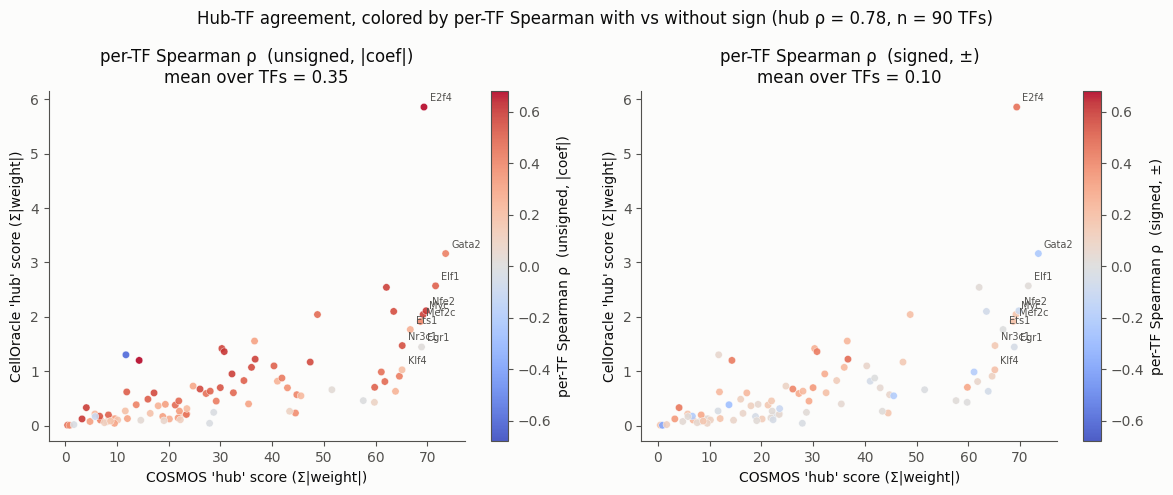

In [12]:
# per-TF union Spearman (signed & unsigned), same instrument as the analysis notebook
def per_tf_union_spearman(pred, ref, signed=True, eps=EPS, min_support=8):
    out = np.full(T, np.nan)
    for t in range(T):
        p, r = pred[:, t], ref[:, t]
        supp = (np.abs(p) > eps) | (np.abs(r) > eps)
        if supp.sum() < min_support:
            continue
        a, b = (p[supp], r[supp]) if signed else (np.abs(p[supp]), np.abs(r[supp]))
        if a.std() == 0 or b.std() == 0:
            continue
        rho = spearmanr(a, b).correlation
        if np.isfinite(rho):
            out[t] = rho
    return out

hub_comet = np.abs(A_learned).sum(axis=0)   # per-TF hub score (Sum |weight|)
hub_co    = np.abs(co_global).sum(axis=0)
hub_rho   = spearmanr(hub_comet, hub_co).correlation
tf_rho_unsigned = per_tf_union_spearman(A_learned, co_global, signed=False)
tf_rho_signed   = per_tf_union_spearman(A_learned, co_global, signed=True)

# diverging color centered at 0 (grey = undefined; blue < 0, red > 0), shared scale
vmax = np.nanmax(np.abs(np.concatenate([tf_rho_unsigned, tf_rho_signed])))
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, shading, label in [(axes[0], tf_rho_unsigned, "per-TF Spearman ρ  (unsigned, |coef|)"),
                           (axes[1], tf_rho_signed,   "per-TF Spearman ρ  (signed, ±)")]:
    cmap = plt.cm.coolwarm.copy(); cmap.set_bad("lightgrey")
    sc = ax.scatter(hub_comet, hub_co, c=shading, cmap=cmap, vmin=-vmax, vmax=vmax,
                    s=28, alpha=0.9, edgecolors="white", linewidths=0.3)
    for ti in np.argsort(hub_comet + hub_co)[-10:]:
        ax.annotate(A_tfs[ti], (hub_comet[ti], hub_co[ti]), fontsize=7,
                    xytext=(4, 4), textcoords="offset points", color=SUB)
    ax.set_xlabel("COSMOS 'hub' score (Σ|weight|)")
    ax.set_ylabel("CellOracle 'hub' score (Σ|weight|)")
    ax.set_title(f"{label}\nmean over TFs = {np.nanmean(shading):.2f}")
    fig.colorbar(sc, ax=ax, label=label)
fig.suptitle(f"Hub-TF agreement, colored by per-TF Spearman with vs without sign "
             f"(hub ρ = {hub_rho:.2f}, n = {T} TFs)", fontsize=12)
fig.tight_layout()
fig.savefig("hub_spearman_sign.png", dpi=150, bbox_inches="tight")
plt.show()

## Figure 4 — COSMOS coefficients skew toward activation

Sign balance of the learned edges. COSMOS assigns positive (activating)
coefficients to a much larger share of edges than CellOracle — both the signed
coefficient distribution (left) and the activating/repressing split (right).

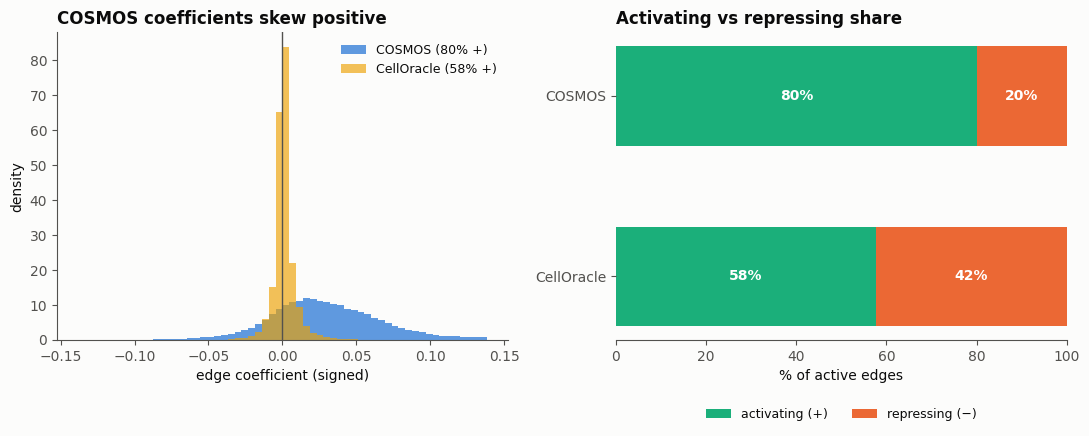

In [13]:
act_green, rep_orange = "#1baf7a", "#eb6834"   # activating / repressing
comet_vals = A_learned[comet_mask]
co_vals    = co_global[co_mask]
comet_pos  = (comet_vals > 0).mean() * 100
co_pos     = (co_vals > 0).mean() * 100

fig, (axH, axB) = plt.subplots(1, 2, figsize=(11, 4.6))

# -- left: signed coefficient distribution over active edges (normalized) --
lim = np.quantile(np.abs(np.r_[comet_vals, co_vals]), 0.99)
bins = np.linspace(-lim, lim, 61)
axH.axvline(0, color=SUB, lw=1)
axH.hist(comet_vals, bins=bins, density=True, color=COMET_C, alpha=0.75, label=f"COSMOS ({comet_pos:.0f}% +)")
axH.hist(co_vals,    bins=bins, density=True, color=CO_C,    alpha=0.65, label=f"CellOracle ({co_pos:.0f}% +)")
axH.set_xlabel("edge coefficient (signed)"); axH.set_ylabel("density")
axH.set_title("COSMOS coefficients skew positive", fontweight="bold", loc="left")
axH.legend(frameon=False, fontsize=9)

# -- right: activating vs repressing share --
yp = [1, 0]; labels = ["COSMOS", "CellOracle"]
pos = [comet_pos, co_pos]; neg = [100 - comet_pos, 100 - co_pos]
axB.barh(yp, pos, color=act_green,  height=0.55, label="activating (+)")
axB.barh(yp, neg, left=pos, color=rep_orange, height=0.55, label="repressing (−)")
for i, p in zip(yp, pos):
    axB.text(p / 2, i, f"{p:.0f}%", ha="center", va="center", color="white", fontweight="bold")
for i, p, n in zip(yp, pos, neg):
    axB.text(p + n / 2, i, f"{n:.0f}%", ha="center", va="center", color="white", fontweight="bold")
axB.set_yticks(yp); axB.set_yticklabels(labels); axB.set_xlim(0, 100)
axB.set_xlabel("% of active edges")
axB.set_title("Activating vs repressing share", fontweight="bold", loc="left")
axB.legend(frameon=False, fontsize=9, ncol=2, loc="lower center", bbox_to_anchor=(0.5, -0.30))
axB.spines["left"].set_visible(False)
fig.tight_layout()
fig.savefig("cosmos_positive_skew.png", dpi=150, bbox_inches="tight")
plt.show()

## Spearman on CellOracle-nonzero edges only

The Spearman values elsewhere use one of two supports per TF: the **union**
(nonzero in either GRN, used by `per_tf_union_spearman` / Fig 3) or the
**intersection** (nonzero in both, used by Fig 2). Here we restrict to the
**CellOracle-nonzero** edges (`co_mask`) regardless of COMET — the stricter,
reference-anchored question: *among the edges CellOracle selected, do the two
methods rank strength / direction the same?*

Restricting to CellOracle's edges drops the unsigned agreement (union removes the
between-group contrast that COMET up-weights CO-selected edges), so this is a
harder test than the union number.

In [14]:
# Spearman restricted to CellOracle-nonzero edges (co_mask), signed & unsigned.
# support: "co" = CellOracle-nonzero only | "union" = either | "intersection" = both.
def per_tf_spearman(pred, ref, support="co", signed=True, eps=EPS, min_support=8):
    out = np.full(T, np.nan)
    for t in range(T):
        p, r = pred[:, t], ref[:, t]
        if support == "co":
            supp = np.abs(r) > eps
        elif support == "intersection":
            supp = (np.abs(p) > eps) & (np.abs(r) > eps)
        else:  # union
            supp = (np.abs(p) > eps) | (np.abs(r) > eps)
        if supp.sum() < min_support:
            continue
        a, b = (p[supp], r[supp]) if signed else (np.abs(p[supp]), np.abs(r[supp]))
        if a.std() == 0 or b.std() == 0:
            continue
        rho = spearmanr(a, b).correlation
        if np.isfinite(rho):
            out[t] = rho
    return out

# global (all CellOracle-nonzero edges pooled)
co_edges = co_mask
p_co, r_co = A_learned[co_edges], co_global[co_edges]
print(f"CellOracle-nonzero edges: {co_edges.sum():,}")
print(f"GLOBAL  (CO-support)  signed ρ = {spearmanr(p_co, r_co).correlation:.3f}"
      f"   unsigned ρ = {spearmanr(np.abs(p_co), np.abs(r_co)).correlation:.3f}\n")

# per-TF, across all three supports for context
print(f"{'support':>13} | {'signed mean/med':>18} | {'unsigned mean/med':>18} | nTF")
for supp in ["co", "intersection", "union"]:
    vs = per_tf_spearman(A_learned, co_global, support=supp, signed=True)
    vu = per_tf_spearman(A_learned, co_global, support=supp, signed=False)
    n = np.isfinite(vu).sum()
    print(f"{supp:>13} | {np.nanmean(vs):>8.3f} / {np.nanmedian(vs):<6.3f} | "
          f"{np.nanmean(vu):>8.3f} / {np.nanmedian(vu):<6.3f} | {n}")

tf_rho_co_unsigned = per_tf_spearman(A_learned, co_global, support="co", signed=False)
tf_rho_co_signed   = per_tf_spearman(A_learned, co_global, support="co", signed=True)

CellOracle-nonzero edges: 13,588
GLOBAL  (CO-support)  signed ρ = 0.096   unsigned ρ = 0.160

      support |    signed mean/med |  unsigned mean/med | nTF
           co |    0.066 / 0.059  |    0.119 / 0.127  | 86
 intersection |    0.070 / 0.061  |    0.123 / 0.128  | 86
        union |    0.097 / 0.072  |    0.346 / 0.381  | 89
